# Démo : stratégies de découpage

**Contexte :** assistant du service client de Lagune Banque.

Un même texte est découpé selon quatre stratégies. Les couleurs distinguent les chunks et les zones d'overlap ; elles montrent ce qui sera transmis au modèle.

Avant de découper, il faut du texte : la première section lit un PDF scanné avec un outil d'OCR.

**Sommaire**
- [Configuration](#configuration)
- [PDF scanné](#ocr)
- [Textes de démonstration](#textes)
- [Visualisation des chunks](#visualisation)
- [Découpage à taille fixe](#taille-fixe)
- [Découpage récursif](#recursif)
- [Découpage par structure](#structure)
- [Découpage sémantique](#semantique)
- [Tableaux](#tableaux)
- [Synthèse](#synthese)

> **Source :** progression inspirée de « 5 Levels of Text Splitting » de Greg Kamradt. Outils de visualisation : <https://chunkviz.up.railway.app/> et <https://chunking.playground.weaviate.io/>.

## <a id="configuration"></a>Configuration

In [1]:
import difflib
import math
import re
import sys
from html import escape
from pathlib import Path

import pandas as pd
import pypdf
from IPython.display import HTML, display
from rapidocr import RapidOCR

sys.path.insert(0, str(next(p for p in [Path("code_partage"), Path("../code_partage"), Path("../../code_partage"), Path("../../../code_partage"), Path("../../code_partage")] if (p / "rag.py").exists()).resolve()))
import rag
from config import prepare

In [2]:
prepare(embedding=True)

Connexion OK : gemini/gemini-3.5-flash-lite gemini/gemini-embedding-2


## <a id="ocr"></a>PDF scanné

La note de service DOC-10 est un scan : le PDF contient une image de la page, pas de texte. `pypdf` n'en extrait rien, et le document serait invisible pour le RAG.

Texte extrait par pypdf : ''


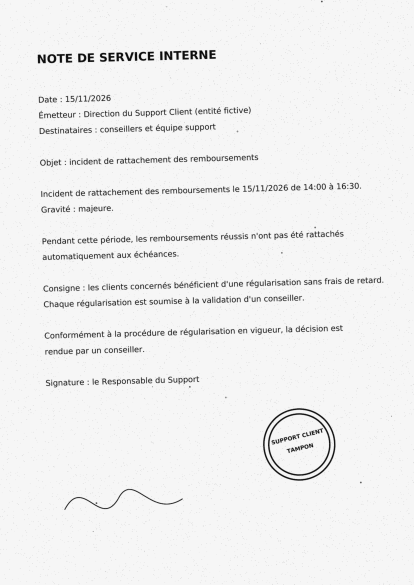

In [3]:
page = pypdf.PdfReader(rag.CORPUS / "note_service_incident.pdf").pages[0]
print("Texte extrait par pypdf :", repr(page.extract_text()))

image = page.images[0].image
display(image.reduce(3))

Un outil d'OCR lit l'image et en tire le texte, ligne par ligne. RapidOCR s'installe avec pip et tourne en local, sans connexion : le document ne sort pas du poste.

In [4]:
ocr = RapidOCR(params={"Global.log_level": "warning"})
resultat = ocr(image)
transcription = "\n".join(resultat.txts)
print(transcription)

NOTEDE SERVICEINTERNE
Date:15/11/2026
Émetteur : Direction du Support Client (entité fictive)
Destinataires : conseillers et équipe support
Objet : incident de rattachement des remboursements
Incident de rattachement des remboursements le 15/11/2026 de 14:00 à 16:30.
Gravité : majeure.
Pendant cette période, les remboursements réussis n'ont pas été rattachés
automatiquement aux échéances.
Consigne : les clients concernés bénéficient d'une régularisation sans frais de retard.
Chaque régularisation est soumise à la validation d'un conseiller.
Conformément à la procédure de régularisation en vigueur, la décision est
rendue par un conseiller.
Signature : le Responsable du Support
SUPPORT CLIENT
TAMPON


Comparaison mot à mot avec la transcription relue, fournie avec le corpus (`note_service_incident.ocr.txt`) : seules les différences sont affichées.

In [5]:
reference = (rag.CORPUS / "note_service_incident.ocr.txt").read_text(encoding="utf-8").split()
mots = transcription.split()
for op, i1, i2, j1, j2 in difflib.SequenceMatcher(None, reference, mots).get_opcodes():
    if op != "equal":
        print(f"{' '.join(reference[i1:i2]) or '(rien)':<45} → {' '.join(mots[j1:j2]) or '(rien)'}")

NOTE DE SERVICE INTERNE Date : 15/11/2026     → NOTEDE SERVICEINTERNE Date:15/11/2026
(rien)                                        → SUPPORT CLIENT TAMPON


Les dates, heures et consignes sont justes. Deux défauts : des espaces disparaissent (« NOTEDE SERVICEINTERNE », « Date:15/11/2026 »), et le tampon est lu comme du texte (« SUPPORT CLIENT », « TAMPON »). Une transcription OCR se relit avant d'être indexée. `rag.load_corpus` utilise la version relue.

## <a id="textes"></a>Textes de démonstration

Deux extraits du corpus : l'article 4 des conditions générales (six clauses numérotées) et le tableau des frais de retard de la grille tarifaire. L'extraction d'un tableau de PDF donne une cellule par ligne.

In [6]:
documents = rag.load_corpus()
for d in documents:
    if d["fichier"].endswith(".pdf") and not d["avertissement"]:
        d["pages"] = rag.strip_headers(d["pages"])
textes = {d["id"]: "\n".join(t for _, t in d["pages"]) for d in documents}

cg = textes["DOC-01"]
debut = cg.index("Article 4 –", cg.index("Article 4 –") + 10)
ARTICLE = cg[debut:cg.index("Article 5 –", debut)].strip()

grille = textes["DOC-06"]
debut = grille.index(" Produit\nFrais de retard")
fin = grille.index("Par échéance impayée", debut) + len("Par échéance impayée")
TABLEAU = grille[debut:fin].strip()

print(ARTICLE)
print("\n---\n")
print(TABLEAU)

Article 4 – Octroi du prêt
4.1 Le Prêt Express est compris entre 5 000 FCFA et 50 000 FCFA. Sa durée est
de 30 jours. Un seul Prêt Express peut être en cours pour un même client.
4.2 Le plafond initial du Prêt Express est de 15 000 FCFA. Il augmente de 5 000
FCFA après chaque série de 2 prêts remboursés à l'échéance, dans la limite de
50 000 FCFA.
4.3 Le Prêt Express+ est compris entre 50 001 FCFA et 300 000 FCFA. Sa durée
est de 30, 60 ou 90 jours. Les échéances sont mensuelles et égales.
4.4 Un nouveau prêt ne peut être accordé que 48 heures après le
remboursement intégral du prêt précédent.
4.5 Le prêt est versé sur le compte Lagune Money du client. L'octroi est décidé
par le système selon les critères publiés, et jamais par l'assistant.
4.6 Le client peut consulter son plafond actuel dans l'application avant de choisir
un montant. Une demande supérieure au plafond n'est pas acceptée.

---

Produit
Frais de retard
Application
Prêt Express
2 000 FCFA
Forfait
Prêt Express+
5 000 FCFA


## <a id="visualisation"></a>Visualisation des chunks

`show` retrouve la position de chaque chunk dans le texte et colore le texte chunk par chunk. Un petit numéro marque le début de chacun. En rouge : l'overlap, présent dans deux chunks. En gris : le texte qui n'est dans aucun chunk.

In [7]:
COULEURS = ["#cfe8ff", "#d7f5d3", "#ffe7b8", "#f4d6ff"]


def show(texte, chunks, titre):
    zones, position = [], 0
    for p in chunks:
        position = texte.find(p, position)
        zones.append((position, position + len(p)))
    bornes = sorted({0, len(texte), *[x for zone in zones for x in zone]})
    debuts = {zone[0]: i for i, zone in enumerate(zones)}
    sortie = ""
    for a, b in zip(bornes, bornes[1:]):
        couvrant = [i for i, (d, f) in enumerate(zones) if d <= a < f]
        fond = "#ff9d9d" if len(couvrant) > 1 else COULEURS[couvrant[0] % 4] if couvrant else "#eeeeee"
        marque = f"<sup><b>{debuts[a]}</b></sup>" if a in debuts else ""
        sortie += f'{marque}<span style="background:{fond}">{escape(texte[a:b])}</span>'
    propres = sum(p.rstrip().endswith((".", "?", "!", ":", ";")) for p in chunks)
    display(HTML(f'<p><b>{titre}</b> : {len(chunks)} chunks, {propres} se terminent par une fin de phrase</p>'
                 f'<pre style="white-space:pre-wrap;line-height:1.5">{sortie}</pre>'))

## <a id="taille-fixe"></a>Découpage à taille fixe

`CharacterTextSplitter` de LangChain, avec `separator=""`, coupe sans regarder le texte : des fenêtres d'au plus 200 caractères, avec 30 caractères d'overlap. Il compte des caractères, il ne lit pas le texte.

In [8]:
from langchain_text_splitters import CharacterTextSplitter

fixe = CharacterTextSplitter(separator="", chunk_size=60, chunk_overlap=0)
show(ARTICLE, fixe.split_text(ARTICLE), "Taille fixe, 200 caractères")

Des chunks se coupent au milieu d'un mot (« initia ») ou d'un nombre (« 000 FCFA »). L'overlap garde ici la clause 4.2 entière dans un chunk, mais les clauses 4.4, 4.5 et 4.6 sont coupées. Le dernier chunk ne contient que « demande supérieure au plafond n'est pas acceptée. » : une question sur le plafond retrouvera ce fragment, sans la phrase qui dit où consulter le plafond.

## <a id="recursif"></a>Découpage récursif

Le splitter de LangChain essaie de couper aux séparateurs les plus forts d'abord : saut de paragraphe, saut de ligne, fin de phrase, espace. Même taille, même overlap.

In [9]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

recursif = RecursiveCharacterTextSplitter(chunk_size=200, chunk_overlap=30, separators=["\n\n", "\n", ". ", " ", ""])
show(ARTICLE, recursif.split_text(ARTICLE), "Récursif, 200 caractères")

La clause 4.2 est ici entière, mais les clauses 4.5 et 4.6 sont coupées en deux chunks : la taille maximale prime sur le sens.

## <a id="structure"></a>Découpage par structure

Le texte porte déjà sa structure : chaque clause commence par un numéro (`4.1`, `4.2`). On coupe à chaque numéro, quelle que soit la taille. Le titre de l'article reste avec la première clause.

In [10]:
debuts = [0] + [m.start() for m in re.finditer(r"(?m)^\d\.\d ", ARTICLE)][1:]
par_structure = [ARTICLE[a:b].strip() for a, b in zip(debuts, debuts[1:] + [len(ARTICLE)])]
show(ARTICLE, par_structure, "Par structure, une clause par chunk")

Chaque chunk est une règle complète : la clause 4.2 est entière. Les tailles varient (de 105 à 178 caractères). Cette méthode demande un texte qui a une structure, et un code adapté à chaque type de document : numéros d'articles, titres HTML, questions d'une FAQ.

## <a id="semantique"></a>Découpage sémantique

On calcule l'embedding de chaque phrase, puis on mesure la distance entre phrases voisines. Quand elle dépasse un seuil, le sujet change : on coupe. Le seuil est ici le 75e centile des distances observées.

In [11]:
phrases = [m.span() for m in re.finditer(r"(?s)\S.*?[.?!](?=\s|$)", ARTICLE)]
vecteurs = rag.embeddings([ARTICLE[a:b] for a, b in phrases])
ecarts = [math.dist(v1, v2) ** 2 for v1, v2 in zip(vecteurs, vecteurs[1:])]
seuil = sorted(ecarts)[int(len(ecarts) * 0.75)]

pd.DataFrame({"phrase": [ARTICLE[a:b][:60].replace("\n", " ") for a, b in phrases[1:]],
              "écart avec la précédente": [round(e, 2) for e in ecarts],
              "split": ["✂" if e >= seuil else "" for e in ecarts]})

,phrase,écart avec la précédente,split
0,Sa durée est de 30 jours.,0.77,✂
1,Un seul Prêt Express peut être en cours pour u...,0.72,
2,4.2 Le plafond initial du Prêt Express est de ...,0.46,
3,Il augmente de 5 000 FCFA après chaque série d...,0.32,
4,4.3 Le Prêt Express+ est compris entre 50 001 ...,0.41,
5,"Sa durée est de 30, 60 ou 90 jours.",0.74,
6,Les échéances sont mensuelles et égales.,0.68,
7,4.4 Un nouveau prêt ne peut être accordé que 4...,0.80,✂
8,4.5 Le prêt est versé sur le compte Lagune Mon...,0.47,
9,L'octroi est décidé par le système selon les c...,0.78,✂


In [12]:
splits = [i for i, e in enumerate(ecarts, 1) if e >= seuil]
groupes = [(splits[i - 1] if i else 0, splits[i] if i < len(splits) else len(phrases)) for i in range(len(splits) + 1)]
semantique = [ARTICLE[phrases[a][0]:phrases[b - 1][1]] for a, b in groupes]
show(ARTICLE, semantique, "Sémantique, seuil au 75e centile")

Sur ce texte, le chunking sémantique est **moins bon** que le chunking par structure : il sépare le montant de la clause 4.1 de sa durée, parce que ces deux phrases parlent de choses différentes. Il convient mieux à des textes continus (comptes rendus, articles) sans numérotation. Il coûte aussi un appel d'embedding par phrase, et le seuil se règle à la main.

## <a id="tableaux"></a>Tableaux

L'extraction d'un tableau de PDF donne une cellule par ligne. Un chunking à taille fixe ne le sait pas.

In [13]:
show(TABLEAU, CharacterTextSplitter(separator="", chunk_size=50, chunk_overlap=8).split_text(TABLEAU), "Taille fixe, 50 caractères")

Le chunk 0 se termine sur « Prêt Express 2 » et le chunk 1 commence par « xpress » : le nom du produit est tronqué. Le dernier chunk ne contient que « 000 FCFA » et « Par échéance impayée », sans le produit auquel ils se rapportent. Une question sur les frais de retard du Prêt Express+ ne trouve pas sa réponse entière dans un même chunk.

Découper par ligne du tableau (trois cellules par ligne) garde chaque produit avec son prix :

In [14]:
cellules = TABLEAU.split("\n")
lignes = ["\n".join(cellules[i:i + 3]) for i in range(0, len(cellules), 3)]
show(TABLEAU, lignes, "Par ligne du tableau")

## <a id="synthese"></a>Synthèse

| Niveau | Coupe selon | Avantage | Limite |
|---|---|---|---|
| 1. Taille fixe | le nombre de caractères | trivial, rapide | coupe mots, phrases et règles |
| 2. Récursif | les séparateurs du texte, sous une taille maximale | bon point de départ | ignore le sens et les tableaux |
| 3. Structure | les titres, numéros, questions du document | chunks complets | un code par type de document |
| 4. Sémantique | les changements de sujet (embeddings) | utile sur du texte continu | un appel par phrase, seuil à régler |
| 5. Agentique | la décision d'un modèle de langage | le plus fin | lent et cher, non montré ici |